In [1]:
import sys
print(sys.executable)

E:\Software\project\homestation\.venv\Scripts\python.exe


In [4]:
import torch
import pandas as pd
import numpy as np
import mysql.connector
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries loaded successfully!")
print("PyTorch:", torch.__version__)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

All libraries loaded successfully!
PyTorch: 2.14.1+cpu
Device: cpu


In [5]:

import mysql.connector
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from mysql.connector import Error

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import classification_report, confusion_matrix

print("Libraries loaded successfully")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)


Libraries loaded successfully
Device: cpu


In [6]:

def get_connection():
    try:
        return mysql.connector.connect(
            host="localhost",
            user="root",
            password="",
            database="marketdata",
        )
    except Error as e:
        print(f"Database connection error: {e}")
        return None


connection = get_connection()

if connection and connection.is_connected():
    print("MySQL connected successfully")
else:
    print("MySQL connection failed")
# Your MySQL table name
TABLE_NAME = "labeled_flatdata"


MySQL connected successfully


In [10]:
import pandas as pd
import numpy as np

# Your MySQL table name
TABLE_NAME = "labeled_flatdata"

TIMEFRAMES = ["H4", "H1", "M15", "M5"]
CANDLE_COUNT = 20
OHLC = ["open", "high", "low", "close"]

# Generate 320 OHLC columns
ohlc_columns = [
    f"{tf}_{i:02d}_{price}"
    for tf in TIMEFRAMES
    for i in range(1, CANDLE_COUNT + 1)
    for price in OHLC
]

print("Total features:", len(ohlc_columns))

Total features: 320


In [11]:
from sqlalchemy import create_engine

engine = create_engine(
    "mysql+mysqlconnector://root:@localhost/marketdata"
)

columns_sql = ", ".join(
    f"`{col}`" for col in ohlc_columns
)

query = f"""
SELECT {columns_sql}
FROM `{TABLE_NAME}`
"""

chunks = pd.read_sql(
    query,
    engine,
    chunksize=10000
)

data = []

for i, chunk in enumerate(chunks):
    chunk = chunk.astype("float32")
    data.append(chunk)

    print(f"Loaded batch {i+1}: {len(chunk)} rows")

df = pd.concat(data, ignore_index=True)

print("\nFinal dataset:", df.shape)

Loaded batch 1: 10000 rows
Loaded batch 2: 10000 rows
Loaded batch 3: 10000 rows
Loaded batch 4: 10000 rows
Loaded batch 5: 10000 rows
Loaded batch 6: 10000 rows
Loaded batch 7: 10000 rows
Loaded batch 8: 10000 rows
Loaded batch 9: 10000 rows
Loaded batch 10: 10000 rows
Loaded batch 11: 10000 rows
Loaded batch 12: 10000 rows
Loaded batch 13: 10000 rows
Loaded batch 14: 10000 rows
Loaded batch 15: 10000 rows
Loaded batch 16: 10000 rows
Loaded batch 17: 10000 rows
Loaded batch 18: 10000 rows
Loaded batch 19: 10000 rows
Loaded batch 20: 10000 rows
Loaded batch 21: 10000 rows
Loaded batch 22: 10000 rows
Loaded batch 23: 10000 rows
Loaded batch 24: 10000 rows
Loaded batch 25: 10000 rows
Loaded batch 26: 10000 rows
Loaded batch 27: 10000 rows
Loaded batch 28: 10000 rows
Loaded batch 29: 10000 rows
Loaded batch 30: 10000 rows
Loaded batch 31: 10000 rows
Loaded batch 32: 10000 rows
Loaded batch 33: 10000 rows
Loaded batch 34: 10000 rows
Loaded batch 35: 10000 rows
Loaded batch 36: 10000 rows
L

In [12]:
X = df.to_numpy(dtype=np.float32)

# Identify valid rows
valid_mask = np.isfinite(X).all(axis=1)

X = X[valid_mask]

print("Valid records:", X.shape[0])
print("Features:", X.shape[1])
print("Data type:", X.dtype)
print("Memory:", round(X.nbytes / (1024**2), 2), "MB")

Valid records: 512485
Features: 320
Data type: float32
Memory: 625.59 MB


In [13]:
# Step 4

from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    X,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (409988, 320)
Testing: (102497, 320)


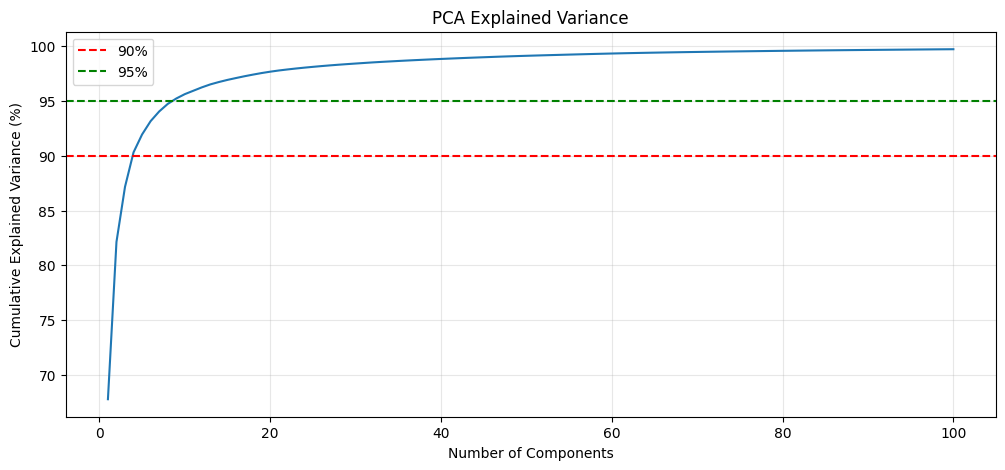

In [14]:
#step 5
from sklearn.decomposition import PCA

pca_test = PCA(
    n_components=100,
    svd_solver="randomized",
    random_state=42
)

pca_test.fit(X_train)

cumulative_variance = np.cumsum(
    pca_test.explained_variance_ratio_
)

plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 101),
    cumulative_variance * 100
)

plt.axhline(90, color="red", linestyle="--", label="90%")
plt.axhline(95, color="green", linestyle="--", label="95%")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
for threshold in [0.80, 0.90, 0.95, 0.99]:

    components = np.argmax(
        cumulative_variance >= threshold
    ) + 1

    print(
        f"{threshold*100:.0f}% variance: "
        f"{components} components"
    )

80% variance: 2 components
90% variance: 4 components
95% variance: 9 components
99% variance: 46 components


In [16]:
#step 6

from sklearn.decomposition import PCA

pca = PCA(
    n_components=46,
    svd_solver="randomized",
    random_state=42
)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Original dimensions:", X_train.shape[1])
print("Reduced dimensions:", X_train_pca.shape[1])

print(
    "Explained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original dimensions: 320
Reduced dimensions: 46
Explained variance: 99.02 %


In [17]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(
    n_clusters=10,
    batch_size=4096,
    random_state=42,
    n_init=5,
    max_iter=200,
    reassignment_ratio=0.01
)

kmeans.fit(X_train_pca)

train_clusters = kmeans.labels_
test_clusters = kmeans.predict(X_test_pca)

print("Clustering completed!")
print("Training samples:", len(train_clusters))
print("Testing samples:", len(test_clusters))

Clustering completed!
Training samples: 409988
Testing samples: 102497


In [18]:
cluster_distribution = pd.DataFrame({
    "Cluster": np.arange(10),
    "Records": np.bincount(train_clusters, minlength=10)
})

cluster_distribution["Percentage"] = (
    cluster_distribution["Records"] /
    len(train_clusters) * 100
)

display(cluster_distribution)

,Cluster,Records,Percentage
0,0,74425,18.152970
1,1,36244,8.840259
2,2,41656,10.160297
3,3,58753,14.330419
4,4,52061,12.698177
5,5,10490,2.558611
6,6,20464,4.991366
7,7,45930,11.202767
8,8,55503,13.537713
9,9,14462,3.527420


C:\Users\nishw\AppData\Local\Temp\ipykernel_9960\3370319242.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


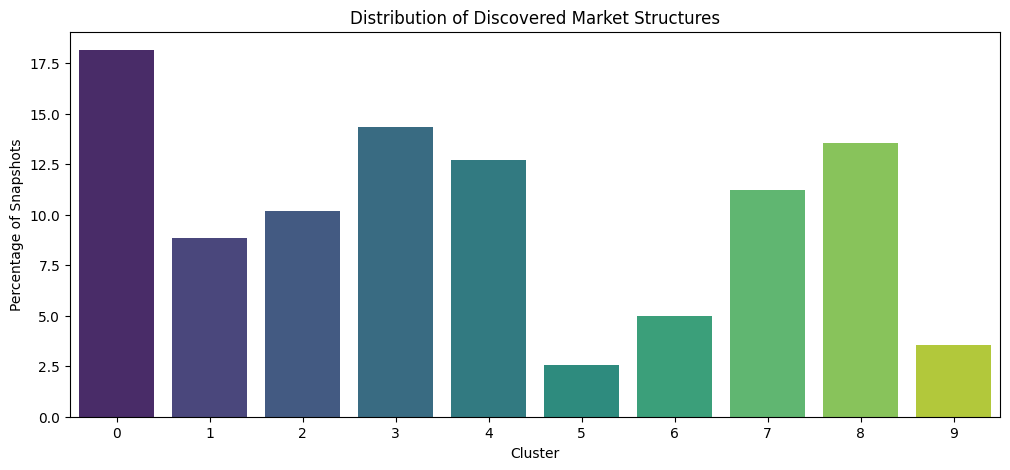

In [19]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=cluster_distribution,
    x="Cluster",
    y="Percentage",
    palette="viridis"
)

plt.title("Distribution of Discovered Market Structures")
plt.ylabel("Percentage of Snapshots")
plt.show()

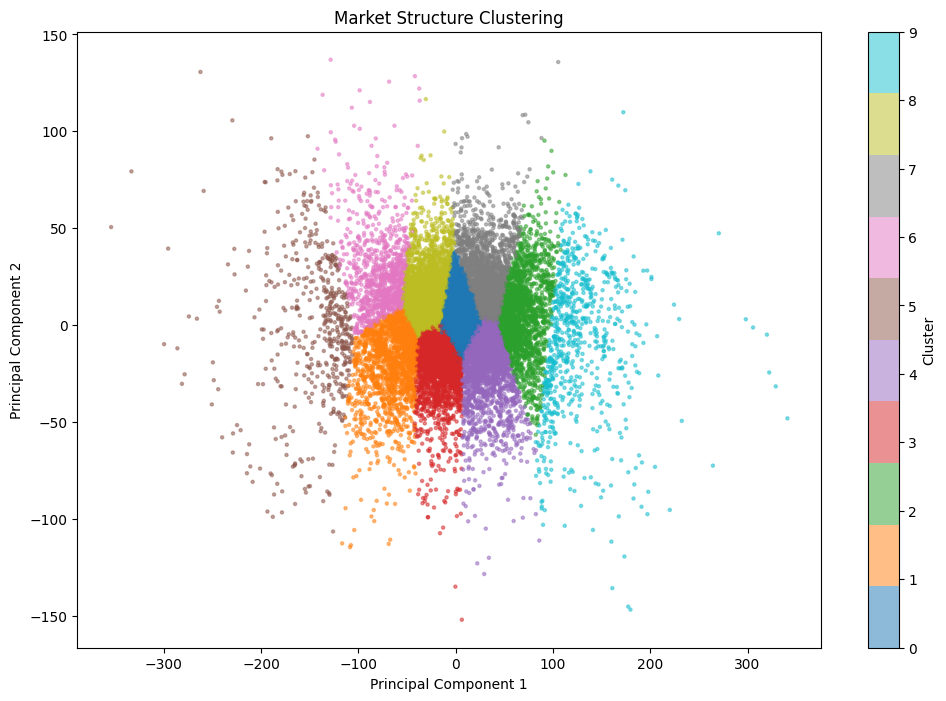

In [20]:
sample_size = min(20000, len(X_train_pca))

rng = np.random.default_rng(42)

indices = rng.choice(
    len(X_train_pca),
    size=sample_size,
    replace=False
)

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    X_train_pca[indices, 0],
    X_train_pca[indices, 1],
    c=train_clusters[indices],
    cmap="tab10",
    s=5,
    alpha=0.5
)

plt.colorbar(scatter, label="Cluster")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Market Structure Clustering")
plt.show()

In [22]:
query = """
SELECT
    CASE
        WHEN decision = 'buy' THEN 'BUY'
        WHEN decision = 'sell' THEN 'SELL'
        ELSE 'WAIT'
    END AS annotation,
    COUNT(*) AS total
FROM labeled_flatdata
WHERE edited = 1
GROUP BY annotation;
"""

annotation_stats = pd.read_sql(query, engine)

display(annotation_stats)

,annotation,total
0,BUY,7
1,SELL,15
2,WAIT,2169


In [24]:
# step 15
# Reconstruct original train/test row indices

from sklearn.model_selection import train_test_split

indices = np.arange(len(X))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training indices:", len(train_indices))
print("Testing indices:", len(test_indices))

Training indices: 409988
Testing indices: 102497


In [25]:
# step 16
# Load ONLY IDs and annotation columns

query = """
SELECT id, decision, edited
FROM labeled_flatdata
"""

metadata = pd.read_sql(query, engine)

print("Metadata shape:", metadata.shape)
display(metadata.head())

Metadata shape: (512485, 3)


,id,decision,edited
0,1,None,1
1,2,None,1
2,3,None,1
3,4,None,1
4,5,None,1


In [26]:
# step 17
# Verify metadata row count against original feature dataset

print("Original X rows:", len(X))
print("Metadata rows:", len(metadata))

print("First database IDs:")
print(metadata["id"].head(10).tolist())

print("Last database IDs:")
print(metadata["id"].tail(10).tolist())

Original X rows: 512485
Metadata rows: 512485
First database IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Last database IDs:
[512476, 512477, 512478, 512479, 512480, 512481, 512482, 512483, 512484, 512485]


In [27]:
# step 18
# Attach existing KMeans cluster assignments to all records

metadata["cluster"] = -1

metadata.loc[train_indices, "cluster"] = train_clusters
metadata.loc[test_indices, "cluster"] = test_clusters

print("Total records:", len(metadata))
print("Assigned records:", (metadata["cluster"] != -1).sum())
print("Unassigned records:", (metadata["cluster"] == -1).sum())

display(metadata.head())

Total records: 512485
Assigned records: 512485
Unassigned records: 0


,id,decision,edited,cluster
0,1,None,1,1
1,2,None,1,1
2,3,None,1,1
3,4,None,1,1
4,5,None,1,1


In [28]:
# step 19
# Analyze all 512K records across discovered clusters

cluster_distribution = (
    metadata["cluster"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_distribution.columns = ["Cluster", "Records"]

cluster_distribution["Percentage"] = (
    cluster_distribution["Records"] /
    len(metadata) * 100
)

display(cluster_distribution)

,Cluster,Records,Percentage
0,0,93052,18.157019
1,1,45335,8.846113
2,2,52229,10.191323
3,3,73171,14.277686
4,4,65111,12.704957
5,5,13121,2.560270
6,6,25522,4.980048
7,7,57450,11.210084
8,8,69276,13.517664
9,9,18218,3.554836


In [29]:
# step 21
# Extract manually reviewed records

reviewed = metadata[metadata["edited"] == 1].copy()

# Normalize annotation labels
reviewed["annotation"] = (
    reviewed["decision"]
    .fillna("WAIT")
    .str.lower()
    .map({
        "buy": "BUY",
        "sell": "SELL",
        "none": "WAIT"
    })
    .fillna("WAIT")
)

print("Total reviewed:", len(reviewed))
print("\nAnnotation distribution:")

display(reviewed["annotation"].value_counts())

Total reviewed: 2191

Annotation distribution:


annotation
WAIT    2169
SELL      15
BUY        7
Name: count, dtype: int64

In [30]:
# step 22
# Compare manual annotations against discovered clusters

cluster_annotations = pd.crosstab(
    reviewed["cluster"],
    reviewed["annotation"]
).reindex(
    index=range(10),
    columns=["BUY", "SELL", "WAIT"],
    fill_value=0
)

display(cluster_annotations)

annotation,BUY,SELL,WAIT
cluster,,,
0,1,1,354
1,1,1,19
2,1,0,274
3,1,3,142
4,2,5,504
5,0,0,0
6,0,0,0
7,1,5,676
8,0,0,128


In [31]:
# step 23
# Calculate percentages within each cluster

cluster_annotation_pct = (
    cluster_annotations.div(
        cluster_annotations.sum(axis=1).replace(0, np.nan),
        axis=0
    ) * 100
)

display(cluster_annotation_pct.round(2))

annotation,BUY,SELL,WAIT
cluster,,,
0,0.28,0.28,99.44
1,4.76,4.76,90.48
2,0.36,0.00,99.64
3,0.68,2.05,97.26
4,0.39,0.98,98.63
5,NaN,NaN,NaN
6,NaN,NaN,NaN
7,0.15,0.73,99.12
8,0.00,0.00,100.00


In [32]:
# step 25
# Identify OHLC columns by timeframe and candle number

timeframes = ["H4", "H1", "M15", "M5"]

ohlc_features = {}

for tf in timeframes:
    ohlc_features[tf] = {}

    for candle in range(1, 21):
        prefix = f"{tf}_{candle:02d}"

        ohlc_features[tf][candle] = [
            f"{prefix}_open",
            f"{prefix}_high",
            f"{prefix}_low",
            f"{prefix}_close"
        ]

print("OHLC feature map created")

for tf in timeframes:
    print(tf, len(ohlc_features[tf]), "candles")

OHLC feature map created
H4 20 candles
H1 20 candles
M15 20 candles
M5 20 candles


In [33]:
# step 26
# Calculate OHLC characteristics for the entire dataset

cluster_stats = []

for tf in timeframes:

    # Get feature indices
    tf_columns = [
        col
        for candle in range(1, 21)
        for col in ohlc_features[tf][candle]
    ]

    tf_indices = [
        ohlc_columns.index(col)
        for col in tf_columns
    ]

    # Extract timeframe data
    tf_data = X[:, tf_indices].reshape(-1, 20, 4)

    open_price = tf_data[:, :, 0]
    high_price = tf_data[:, :, 1]
    low_price = tf_data[:, :, 2]
    close_price = tf_data[:, :, 3]

    body = close_price - open_price

    candle_range = high_price - low_price

    upper_wick = high_price - np.maximum(
        open_price, close_price
    )

    lower_wick = np.minimum(
        open_price, close_price
    ) - low_price

    bullish = (close_price > open_price).mean(axis=1)
    bearish = (close_price < open_price).mean(axis=1)

    features = pd.DataFrame({
        "cluster": metadata["cluster"].values,
        "bullish_pct": bullish * 100,
        "bearish_pct": bearish * 100,
        "avg_body": np.abs(body).mean(axis=1),
        "avg_range": candle_range.mean(axis=1),
        "avg_upper_wick": upper_wick.mean(axis=1),
        "avg_lower_wick": lower_wick.mean(axis=1)
    })

    grouped = features.groupby("cluster").mean()

    grouped["timeframe"] = tf

    cluster_stats.append(grouped.reset_index())

cluster_profiles = pd.concat(
    cluster_stats,
    ignore_index=True
)

display(cluster_profiles.round(5))

,cluster,bullish_pct,bearish_pct,avg_body,avg_range,avg_upper_wick,avg_lower_wick,timeframe
0,0,49.09212,50.38387,1.15051,2.41222,0.65208,0.60964,H4
1,1,59.90372,39.68854,1.60440,3.17143,0.82799,0.73903,H4
2,2,42.03728,57.53585,1.48212,2.96155,0.74939,0.73004,H4
3,3,55.00834,44.59909,1.35494,2.76743,0.74527,0.66722,H4
4,4,48.27556,51.28826,1.37560,2.77364,0.72508,0.67296,H4
5,5,63.94101,36.01250,2.30703,4.37541,1.12386,0.94452,H4
6,6,57.67456,42.04549,1.62266,3.21034,0.83426,0.75343,H4
7,7,44.29138,55.28956,1.38112,2.79127,0.71384,0.69630,H4
8,8,53.57858,46.06364,1.30805,2.68188,0.71652,0.65730,H4
9,9,40.64579,58.93539,2.07302,3.93896,0.93662,0.92932,H4


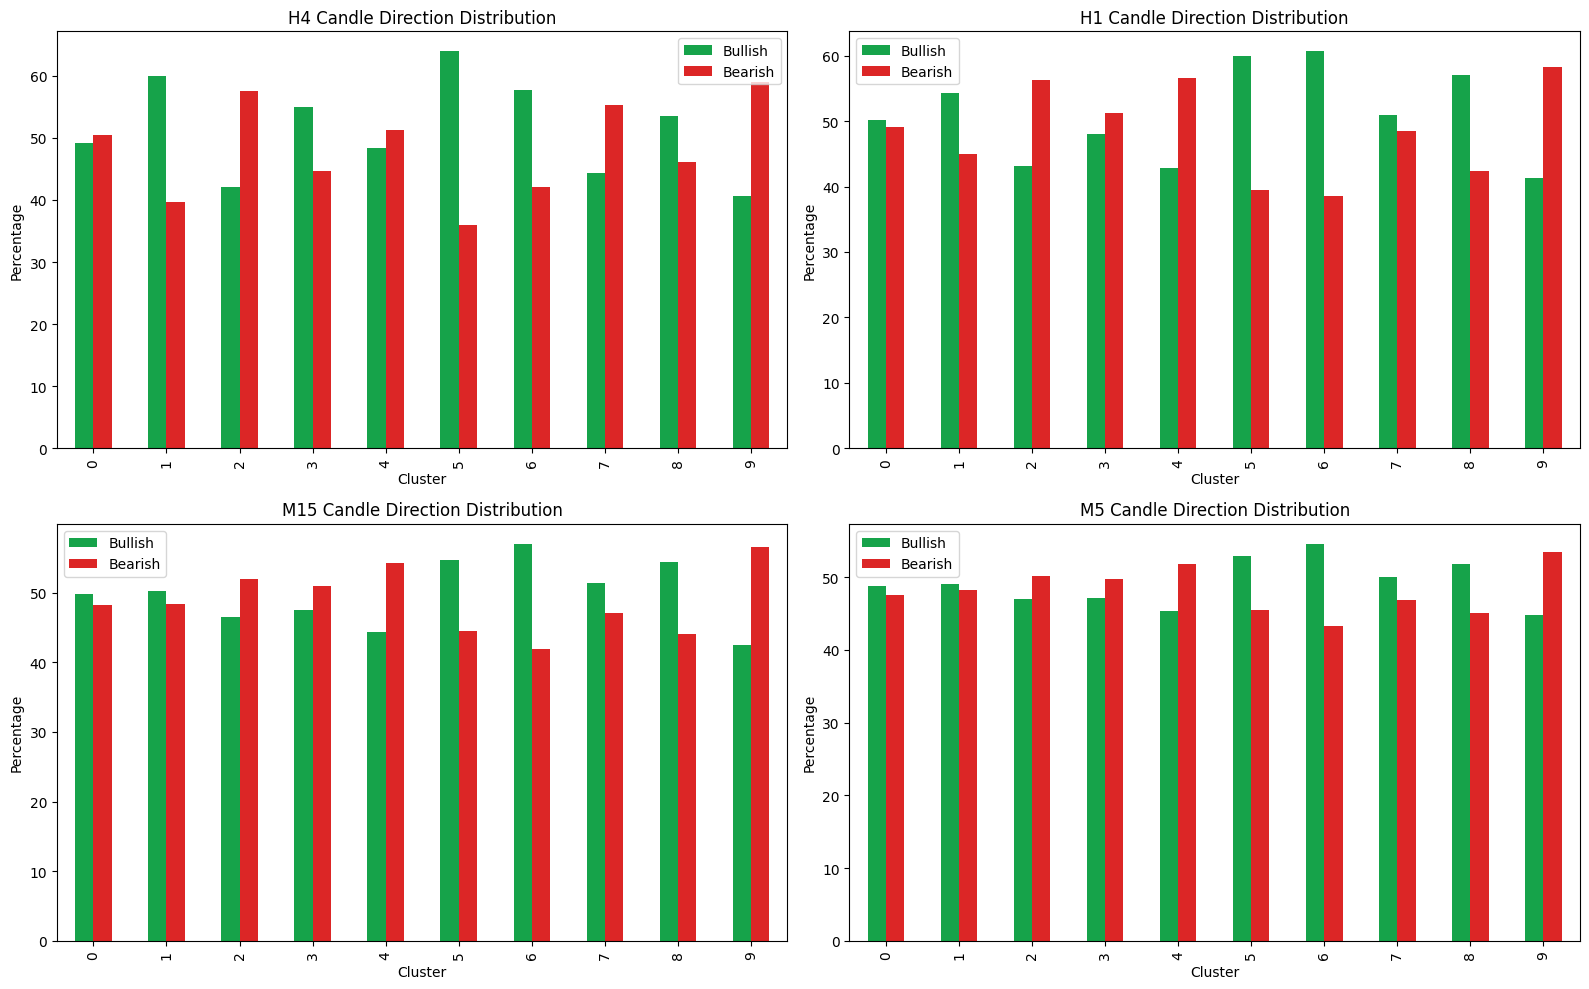

In [34]:
# step 27
# Compare bullish and bearish candle proportions

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10)
)

for ax, tf in zip(axes.flatten(), timeframes):

    subset = cluster_profiles[
        cluster_profiles["timeframe"] == tf
    ]

    subset.set_index("cluster")[
        ["bullish_pct", "bearish_pct"]
    ].plot(
        kind="bar",
        ax=ax,
        color=["#16a34a", "#dc2626"]
    )

    ax.set_title(f"{tf} Candle Direction Distribution")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Percentage")
    ax.legend(["Bullish", "Bearish"])

plt.tight_layout()
plt.show()